# SpikeDistill-RUL — end-to-end notebook
**Md Minhaj Uddin · 2401CS39 · Machine Learning, IIT Patna**

Distilling an attention-BiLSTM into a recurrent spiking network for remaining-useful-life (RUL) prediction on NASA C-MAPSS.

**How this notebook is organised.** (1) data and audit, (2) the leakage-free protocol, (3) baselines, (4) teacher and spiking student, (5) the full results that were computed with `scripts/run_suite.py`, (6) explainability, (7) energy.
Sections 3–4 *train* a reduced version of the pipeline on FD001 (`QUICK = True`, a few epochs, one seed) so that the notebook runs end to end in minutes; the 8-seed, four-subset numbers in section 5 are read from `results/`.
Run from the repository root (`jupyter nbconvert --execute 2401CS39_MLProject.ipynb`).

In [1]:
import json, os, sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT / "scripts"))
from rul.data import load_raw, prepare
from rul.models import create_model, count_params
from rul.train import fit, predict
from rul.distill import fit_distillation
from rul.metrics import all_metrics
from rul.energy import count_macs, energy_pj

QUICK = True                      # False: longer training (about 3x slower)
SEED, SUBSET = 0, "FD001"
WIN = json.load(open(ROOT / "results/window_choice_v2.json"))["window"]     # chosen on validation data (see section 5)
torch.set_num_threads(4); torch.manual_seed(SEED); np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
print("torch", torch.__version__, "| window", WIN, "| subset", SUBSET, "| QUICK", QUICK)

torch 2.15.0 | window 60 | subset FD001 | QUICK True


## 1  Data and audit
C-MAPSS is a simulator of turbofan degradation (Saxena et al., PHM 2008). Each row is one engine at one flight cycle: 3 operational settings + 21 sensors. Training engines run to failure; each test engine is cut at a random cycle and has one true RUL.

In [2]:
train, test, true_rul = load_raw(SUBSET, str(ROOT / "data/raw"))
audit = {
 "train engines": train["engine"].nunique(), "test engines": test["engine"].nunique(), "train rows": len(train), "test rows": len(test),
 "missing values": int(train.isna().sum().sum() + test.isna().sum().sum()), "duplicate (engine, cycle) rows": int(train.duplicated(["engine", "cycle"]).sum()),
 "constant sensors": [c for c in train.columns if c.startswith("s") and train[c].std() < 1e-6],
 "test labels above the 125 cap": int((true_rul > 125).sum()),
}
pd.Series(audit)

train engines                                                        100
test engines                                                         100
train rows                                                         20631
test rows                                                          13096
missing values                                                         0
duplicate (engine, cycle) rows                                         0
constant sensors                  [setting3, s1, s5, s10, s16, s18, s19]
test labels above the 125 cap                                         11
dtype: object

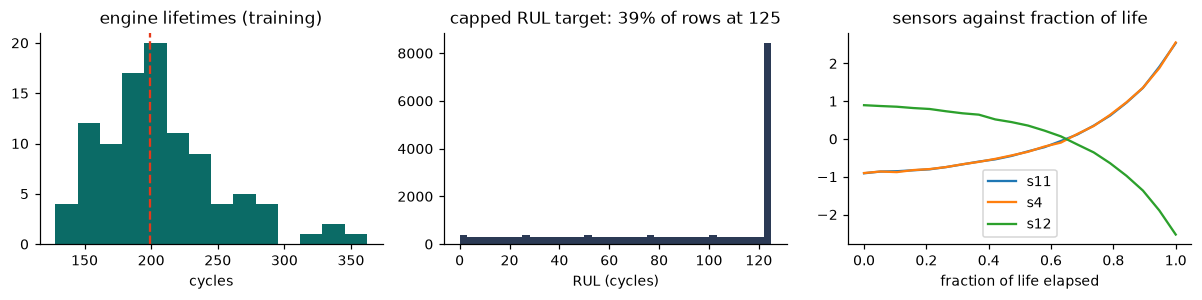

In [3]:
life = train.groupby("engine")["cycle"].max()
rul = train.assign(rul=train.groupby("engine")["cycle"].transform("max") - train["cycle"])
fig, ax = plt.subplots(1, 3, figsize=(11, 2.8))
ax[0].hist(life, bins=14, color="#0B6B66"); ax[0].axvline(life.median(), color="#E5391A", ls="--"); ax[0].set_title("engine lifetimes (training)"); ax[0].set_xlabel("cycles")
ax[1].hist(rul["rul"].clip(upper=125), bins=40, color="#2B3A55"); ax[1].set_title(f"capped RUL target: {(rul['rul']>=125).mean()*100:.0f}% of rows at 125"); ax[1].set_xlabel("RUL (cycles)")
for s in ["s11", "s4", "s12"]:
    f = (rul["cycle"] / rul.groupby("engine")["cycle"].transform("max")); g = rul.assign(frac=pd.cut(f, 20, labels=False))
    z = g.groupby("frac")[s].mean(); ax[2].plot(z.index / 19, (z - z.mean()) / z.std(), label=s)
ax[2].legend(); ax[2].set_title("sensors against fraction of life"); ax[2].set_xlabel("fraction of life elapsed")
plt.tight_layout(); plt.show()

**Reading the figures.** Lifetimes vary by a factor of about 2.8, so a model must read the sensor trend and cannot count cycles. About 39% of training rows have RUL ≥ 125: an engine early in life looks healthy whatever its true RUL, so the target is capped at 125 (accuracy is only learnable in the last 125 cycles). The sensors separate in the last 40% of life.

## 2  Leakage-free protocol
The split is made **by engine** (never by window); the sensor filter and the scaler are fitted on the fit engines only; the validation set contains every cut of every held-out engine whose true RUL is in [1, 125] windowed like a test engine (the *test-like* validation set, identical for every window length).

In [4]:
d = prepare(SUBSET, data_dir=str(ROOT / "data/raw"), window=WIN, seed=SEED)
assert not (set(d["train_engines"]) & set(d["val_engines"])), "an engine is in both fit and validation sets"
S = len(d["sensors"]); print("sensors kept:", S, d["sensors"])
print({k: v.shape for k, v in d.items() if hasattr(v, "shape")})
# the min-max scaler was fitted on the fit engines only: its minima/maxima equal those of the fit engines, not of validation or test engines
fit_rows = train[train["engine"].isin(d["train_engines"])]
print("scaler min/max == fit-engine min/max:", np.allclose(d["scaler"]["min"].to_numpy(), fit_rows[d["sensors"]].min().to_numpy()) and np.allclose(d["scaler"]["max"].to_numpy(), fit_rows[d["sensors"]].max().to_numpy()))
print("fit engines:", len(d["train_engines"]), "| validation engines:", len(d["val_engines"]), "| test engines:", len(d["y_test"]), "(three disjoint sets of engines)")
print("test-like validation cuts:", len(d["y_val_tl"]), "| label range", d["y_val_tl"].min(), d["y_val_tl"].max())

sensors kept: 14 ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']
{'X_train': (11580, 60, 14), 'y_train': (11580,), 'X_val': (3151, 60, 14), 'y_val': (3151,), 'X_val_pseudo': (20, 60, 14), 'y_val_pseudo': (20,), 'X_val_tl': (2500, 60, 14), 'y_val_tl': (2500,), 'X_test': (100, 60, 14), 'y_test': (100,), 'train_engines': (80,), 'val_engines': (20,)}
scaler min/max == fit-engine min/max: True
fit engines: 80 | validation engines: 20 | test engines: 100 (three disjoint sets of engines)
test-like validation cuts: 2500 | label range 1.0 125.0


Two label conventions are reported everywhere. NASA's test labels are uncapped but our predictions stop at 125, so we report **official** RMSE (against the unmodified labels) and **capped** RMSE (against `min(RUL, 125)`, the quantity the models are trained for).

In [5]:
def score(pred, y):
    pred = np.clip(np.asarray(pred, float), 0, 125); y = np.asarray(y, float); yc = np.minimum(y, 125)
    m = all_metrics(y, pred)
    return {"RMSE (official)": m["RMSE"], "RMSE (capped)": float(np.sqrt(np.mean((pred - yc) ** 2))), "MAE": m["MAE"], "R2": m["R2"], "NASA score": m["Score"]}
results = {}

## 3  Baselines
First the simple ones: a constant predictor and ridge regression / gradient boosting on hand-made window features (last value, mean, change and standard deviation of every sensor). Then two neural baselines trained with the same split, windows and early stopping on the test-like validation set.

In [6]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
feats = lambda X: np.concatenate([X[:, -1], X.mean(1), X[:, -1] - X[:, 0], X.std(1)], axis=1)
Ftr, Fte = feats(d["X_train"]), feats(d["X_test"])
results["constant"] = {**score(np.full(len(d["y_test"]), d["y_train"].mean()), d["y_test"]), "params": 0}
results["ridge (features)"] = {**score(Ridge(alpha=100).fit(Ftr, d["y_train"]).predict(Fte), d["y_test"]), "params": Ftr.shape[1] + 1}
gbm = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.06, random_state=SEED).fit(Ftr, d["y_train"])
results["gradient boosting (features)"] = {**score(gbm.predict(Fte), d["y_test"]), "params": np.nan}
pd.DataFrame(results).T.round(2)

,RMSE (official),RMSE (capped),MAE,R2,NASA score,params
constant,41.75,40.18,37.34,-0.01,9296.69,0.0
ridge (features),18.52,16.75,14.67,0.80,470.08,57.0
gradient boosting (features),18.74,17.26,13.38,0.80,763.65,NaN


In [7]:
EP = 10 if QUICK else 40
for name, kw in (("gru", {}), ("tcn", {"dilations": (1, 2, 4, 8, 16, 32)})):
    t0 = time.time(); torch.manual_seed(SEED)
    m = create_model(name, S, **kw)
    r = fit(m, d, epochs=EP, patience=5, device="cpu", verbose=False, y_scale=125.0, select="tl")
    p = predict(m, d["X_test"], "cpu", y_scale=125.0)
    results[name.upper()] = {**score(p, d["y_test"]), "params": count_params(m), "val (test-like)": r["val_tl"]["RMSE"], "train s": time.time() - t0, "epochs": r["epochs_run"]}
    print(name, "done", round(time.time() - t0), "s")
pd.DataFrame(results).T.round(2)

gru done 9 s


tcn done 46 s


,RMSE (official),RMSE (capped),MAE,R2,NASA score,params,val (test-like),train s,epochs
constant,41.75,40.18,37.34,-0.01,9296.69,0.0,NaN,NaN,NaN
ridge (features),18.52,16.75,14.67,0.80,470.08,57.0,NaN,NaN,NaN
gradient boosting (features),18.74,17.26,13.38,0.80,763.65,NaN,NaN,NaN,NaN
GRU,14.50,13.31,10.96,0.88,320.80,17473.0,12.79,9.33,10.0
TCN,15.68,14.46,11.44,0.86,356.47,20193.0,13.10,46.29,10.0


## 4  Teacher and spiking student
**Teacher**: a two-layer bidirectional LSTM with additive attention over time (152,769 parameters on FD001). **Student**: two recurrent leaky integrate-and-fire layers of 48 neurons with learnable leak β and threshold V<sub>th</sub>; the readout is attention over the *membrane voltages* of layer 2. The spike is a step function; in the backward pass its derivative is replaced by a fast sigmoid 1/(1+α|v−V<sub>th</sub>|)² (surrogate gradient).

The distillation loss is  `L = SmoothL1(ŷ, y) + 0.5·MSE(ŷ, ŷ_T) + 0.2·[1 − cos(P·v, h_T)] + 0.1·KL(a_T ‖ a_S) + 1.0·max(0, ρ − 0.15)²`
(task, output, hidden-trajectory, attention, firing-rate budget); the teacher is frozen.

In [8]:
t0 = time.time(); torch.manual_seed(SEED)
teacher = create_model("teacher", S)
rt = fit(teacher, d, epochs=EP, patience=5, device="cpu", verbose=False, y_scale=125.0, select="tl")
results["Attn-BiLSTM (teacher)"] = {**score(predict(teacher, d["X_test"], "cpu", y_scale=125.0), d["y_test"]), "params": count_params(teacher), "val (test-like)": rt["val_tl"]["RMSE"], "train s": time.time() - t0, "epochs": rt["epochs_run"]}
print("teacher", round(time.time() - t0), "s", "| params", count_params(teacher))

teacher 45 s | params 152769


In [9]:
spike_runs = {}
for tag, tch in (("spiking student, no teacher", None), ("spiking student + distillation", teacher)):
    t0 = time.time(); torch.manual_seed(SEED)
    st = create_model("student", S)
    r = fit_distillation(st, tch, d, epochs=EP, patience=5, device="cpu", verbose=False, select="tl")
    p = predict(st, d["X_test"], "cpu", y_scale=125.0)
    ops = st.ops(WIN, r["rate1"], r["rate2"])
    results[tag] = {**score(p, d["y_test"]), "params": count_params(st), "val (test-like)": r["val_tl"]["RMSE"], "train s": time.time() - t0, "epochs": r["epochs_run"],
                    "spike rate": r["test_spike_rate"], "energy nJ": energy_pj(ops["macs"], ops["acs"]) / 1000}
    spike_runs[tag] = (st, r)
    print(tag, round(time.time() - t0), "s | spike rate", round(r["test_spike_rate"], 3))
tab = pd.DataFrame(results).T
tab[["params", "RMSE (capped)", "RMSE (official)", "MAE", "R2", "NASA score", "val (test-like)", "spike rate", "energy nJ", "train s"]].round(2)

spiking student, no teacher 10 s | spike rate 0.153


spiking student + distillation 30 s | spike rate 0.176


,params,RMSE (capped),RMSE (official),MAE,R2,NASA score,val (test-like),spike rate,energy nJ,train s
constant,0.0,40.18,41.75,37.34,-0.01,9296.69,NaN,NaN,NaN,NaN
ridge (features),57.0,16.75,18.52,14.67,0.80,470.08,NaN,NaN,NaN,NaN
gradient boosting (features),NaN,17.26,18.74,13.38,0.80,763.65,NaN,NaN,NaN,NaN
GRU,17473.0,13.31,14.50,10.96,0.88,320.80,12.79,NaN,NaN,9.33
TCN,20193.0,14.46,15.68,11.44,0.86,356.47,13.10,NaN,NaN,46.29
Attn-BiLSTM (teacher),152769.0,13.34,14.44,10.56,0.88,366.83,13.11,NaN,NaN,45.24
"spiking student, no teacher",10273.0,16.97,18.16,13.58,0.81,717.44,18.42,0.15,510.25,10.45
spiking student + distillation,10273.0,16.57,17.83,13.08,0.82,474.13,18.40,0.18,521.02,29.67


These are single-seed, reduced-epoch runs for illustration. With so few epochs and one seed, differences of a fraction of a cycle are not meaningful: the test sets (100 engines in FD001) cannot resolve them (see section 5). The paired, 8-seed comparison is below.

## 5  Full results (computed with `scripts/run_suite.py`, read from `results/`)
18 dense architectures × 4 subsets × 5–8 seeds, the window sweep, the distillation study (8 seeds, paired), ablations (5 seeds) and pooled training, all under the same leakage-free protocol.

In [10]:
A2 = json.load(open(ROOT / "results/analysis_v2.json"))
SUBS = ["FD001", "FD002", "FD003", "FD004"]
bench = pd.DataFrame({m: {"params": int(r["params"]["mean"]), "val RMSE (test-like)": r["val_tl"]["mean"], "test RMSE": r["rmse"]["mean"], "test RMSE (capped)": r["rmse_c125"]["mean"],
                         "sd (capped)": r["rmse_c125"]["sd"], "MAE": r["mae"]["mean"], "R2": r["r2"]["mean"], "NASA score": r["score"]["mean"], "train s": r["seconds"]["mean"], "seeds": r["rmse"]["n"]}
                      for m, r in A2["main"]["FD001"].items()}).T.sort_values("test RMSE (capped)")
print("FD001, window", WIN, "- all models"); bench.round(2)

FD001, window 60 - all models


,params,val RMSE (test-like),test RMSE,test RMSE (capped),sd (capped),MAE,R2,NASA score,train s,seeds
deepnn,116353.0,12.06,14.30,13.05,0.35,10.59,0.88,285.65,8.70,8.0
mamba2,35221.0,11.45,14.24,13.05,0.38,10.47,0.88,301.15,1174.91,5.0
bimambateacher,47105.0,11.55,14.33,13.09,0.31,10.76,0.88,283.86,2027.51,5.0
cnnbigruattn,37089.0,11.64,14.62,13.38,0.49,10.88,0.88,297.86,147.87,8.0
bimamba,42881.0,12.27,14.82,13.57,0.60,10.90,0.87,306.63,2481.96,5.0
teacher,152769.0,11.49,14.86,13.66,0.51,11.04,0.87,314.72,369.16,8.0
bilstm,45121.0,11.70,15.15,13.86,0.57,11.28,0.87,313.89,165.07,8.0
gru,17473.0,11.72,15.31,14.16,0.61,11.29,0.86,338.88,54.29,8.0
transformerteacher,111553.0,12.40,15.40,14.17,0.62,11.45,0.86,348.80,717.46,8.0
transformer,20577.0,12.20,15.42,14.30,0.75,11.34,0.86,362.57,536.93,8.0


In [11]:
cap = pd.DataFrame({s: {m: r["rmse_c125"]["mean"] for m, r in A2["main"][s].items()} for s in SUBS})
tied = pd.DataFrame({s: {m: v["tied_with_best"] for m, v in A2["ties"][s]["models"].items()} for s in SUBS})
print("capped-label test RMSE; the model marked * is statistically tied with the best on that subset (paired bootstrap over test engines)")
cap.round(2).astype(str).where(~tied.reindex(cap.index).fillna(False), cap.round(2).astype(str) + " *").loc[cap.mean(axis=1).sort_values().index]

capped-label test RMSE; the model marked * is statistically tied with the best on that subset (paired bootstrap over test engines)


,FD001,FD002,FD003,FD004
teacher,13.66,12.41 *,12.56 *,13.27 *
cnnbigruattn,13.38,12.86 *,12.56 *,13.48 *
gru,14.16,12.96,12.39 *,13.18 *
mamba2,13.05 *,13.62 *,11.79 *,14.36 *
tcn,14.38,12.95 *,12.01 *,13.59 *
bilstm,13.86,12.72 *,13.54 *,13.9
deepnn,13.05 *,14.87,12.87 *,13.42 *
bimamba,13.57,13.7 *,13.31,13.75 *
lstm,14.75,12.82 *,13.25 *,13.62 *
tcnattn,14.74,13.87,12.63 *,13.71 *


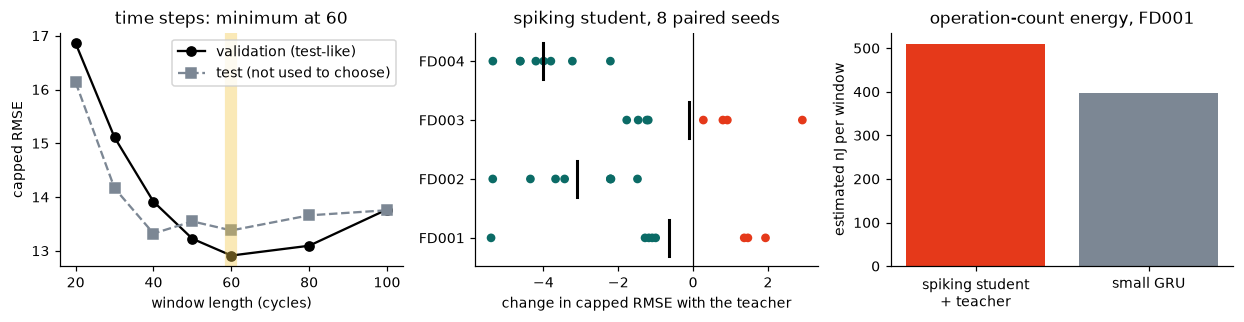

,subset,student,no teacher,with teacher,delta,p (paired t),seeds improved
0,FD001,spike,16.055,15.406,-0.649,0.461,5/8
1,FD001,smallgru,13.638,14.071,0.434,0.420,3/8
2,FD001,smalllstm,14.394,14.355,-0.039,0.792,4/8
3,FD002,spike,17.735,14.621,-3.113,0.000,8/8
4,FD002,smallgru,13.097,12.983,-0.114,0.580,4/8
5,FD002,smalllstm,14.329,14.080,-0.249,0.627,4/8
6,FD003,spike,16.394,16.297,-0.097,0.870,4/8
7,FD003,smallgru,12.913,12.795,-0.117,0.459,4/8
8,FD003,smalllstm,13.501,14.115,0.614,0.279,3/8
9,FD004,spike,18.990,14.988,-4.002,0.000,8/8


In [12]:
wc = json.load(open(ROOT / "results/window_choice_v2.json"))["table"]
W = sorted(int(k) for k in wc)
fig, ax = plt.subplots(1, 3, figsize=(11.5, 3))
ax[0].plot(W, [wc[str(w)]["val_tl_rmse"] for w in W], "o-", color="k", label="validation (test-like)")
ax[0].plot(W, [wc[str(w)]["test_rmse_capped"] for w in W], "s--", color="#7C8794", label="test (not used to choose)")
ax[0].axvline(WIN, color="#F3C94B", lw=8, alpha=.4); ax[0].set_xlabel("window length (cycles)"); ax[0].set_ylabel("capped RMSE"); ax[0].legend(); ax[0].set_title(f"time steps: minimum at {WIN}")
dist = A2["distill"]
for k, s in enumerate(SUBS):
    dif = dist[s]["spike"]["c125"]["diffs"]; ax[1].scatter(dif, [k] * len(dif), color=["#0B6B66" if x < 0 else "#E5391A" for x in dif], s=22)
    ax[1].plot([np.mean(dif)] * 2, [k - .3, k + .3], "k", lw=2)
ax[1].axvline(0, color="k", lw=.8); ax[1].set_yticks(range(4)); ax[1].set_yticklabels(SUBS); ax[1].set_xlabel("change in capped RMSE with the teacher"); ax[1].set_title("spiking student, 8 paired seeds")
en = A2["energy"]["FD001"]; names = ["spike/teacher", "smallgru/none"]
ax[2].bar(["spiking student\n+ teacher", "small GRU"], [en[n]["energy_nj"]["mean"] for n in names], color=["#E5391A", "#7C8794"]); ax[2].set_ylabel("estimated nJ per window"); ax[2].set_title("operation-count energy, FD001")
plt.tight_layout(); plt.show()
rows = []
for s in SUBS:
    for st in ("spike", "smallgru", "smalllstm"):
        r = dist[s][st]; k = r["c125"]; rows.append({"subset": s, "student": st, "no teacher": r["none"]["mean"], "with teacher": r["teacher"]["mean"], "delta": k["mean"], "p (paired t)": k["p"], "seeds improved": f"{k['improved']}/{k['n']}"})
pd.DataFrame(rows).round(3)

**Reading.** (i) The window error is U-shaped, minimum at the chosen value on validation data; the test curve is flat across 40–80 cycles because 100–259 test engines cannot resolve fractions of a cycle. (ii) Distillation helps the *spiking* student significantly on FD002 and FD004 (all 8 seeds improve) and does nothing measurable for small dense students or on FD001/FD003: a teacher can only help where the student has a gap to close. (iii) By operation counting the spiking student is **not** cheaper than a small GRU, because most of its energy is dense multiplication (analog input layer and attention readout).

## 6  Explainability (student trained above)
Five methods are used in the report; here three are shown for the student trained in section 4: permutation importance, attention maps and Integrated Gradients on a sample of test windows. (Exact Shapley values for 14 sensors take longer and are in `scripts/xai.py` and `results/xai/xai.json`.)

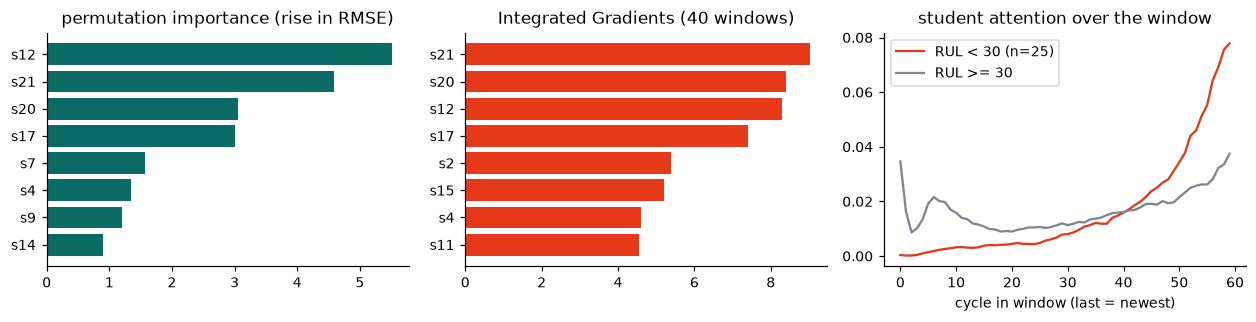

IG completeness gap (|sum(IG) - (f(x) - f(baseline))| / mean|f(x) - f(baseline)|), spiking student: 87%


In [13]:
import xai                                   # scripts/xai.py (functions only; main() is not run)
st = spike_runs["spiking student + distillation"][0].eval()
X = torch.as_tensor(d["X_test"]); y = d["y_test"]
perm, base = xai.permutation_importance(st, d["X_test"], y, repeats=5)
base_in = torch.as_tensor(d["X_train"].mean(axis=(0, 1)), dtype=torch.float32).expand(X.shape[1], S).contiguous()
ig, gap = xai.integrated_gradients(st, X[:40], base_in, steps=16)
ig_s = ig.abs().sum(dim=1).mean(0).numpy()
with torch.no_grad():
    _, _, _, att, _ = st.forward_with_internals(X)
near = torch.as_tensor(y < 30)
order = np.argsort(-perm)
fig, ax = plt.subplots(1, 3, figsize=(11.5, 3))
ax[0].barh([d["sensors"][i] for i in order[:8]][::-1], perm[order[:8]][::-1], color="#0B6B66"); ax[0].set_title("permutation importance (rise in RMSE)")
ax[1].barh([d["sensors"][i] for i in np.argsort(-ig_s)[:8]][::-1], np.sort(ig_s)[::-1][:8][::-1], color="#E5391A"); ax[1].set_title("Integrated Gradients (40 windows)")
ax[2].plot(att[near].mean(0), label=f"RUL < 30 (n={int(near.sum())})", color="#E5391A"); ax[2].plot(att[~near].mean(0), label="RUL >= 30", color="#7C8794"); ax[2].legend(); ax[2].set_title("student attention over the window"); ax[2].set_xlabel("cycle in window (last = newest)")
plt.tight_layout(); plt.show()
print("IG completeness gap (|sum(IG) - (f(x) - f(baseline))| / mean|f(x) - f(baseline)|), spiking student: %.0f%%" % (100 * float(gap.abs().mean()) / max(1e-9, float((st(X[:40]) * 125 - st(base_in[None]) * 125).abs().mean()))))

Attributions describe the **model**, not the engine physics. Integrated Gradients' completeness check is weak for the spiking student (the output is piecewise constant in the input because spikes are binary), which is why the report relies on Shapley and permutation values for it.

## 7  Energy accounting
Energy is **counted** from operations, not measured: one multiply-accumulate (MAC) costs 4.6 pJ and one spike-triggered accumulate (AC) 0.9 pJ (32-bit float, 45 nm, Horowitz ISSCC 2014). In the student, the first layer reads analog values (dense MACs), everything fed by spikes is an AC that happens only when a spike arrives, and the attention readout is dense.

In [14]:
st, r = spike_runs["spiking student + distillation"]
ops = st.ops(WIN, r["rate1"], r["rate2"])
gru = create_model("smallgru", S)
parts = {"input layer (analog -> MAC)": WIN * S * 48 * 4.6, "attention readout (MAC)": (WIN * (48 * 16 + 16) + WIN * 48) * 4.6, "decay + head (MAC)": (2 * WIN * 48 + 48 * 32 + 32) * 4.6, "spike accumulates (AC)": ops["acs"] * 0.9}
tot = sum(parts.values()); print(pd.Series({k: f"{v/1000:.0f} nJ ({100*v/tot:.0f}%)" for k, v in parts.items()}))
print("student total %.0f nJ at firing rate %.1f%%;  small GRU (dense) %.0f nJ" % (tot / 1000, 100 * r["test_spike_rate"], energy_pj(count_macs(gru, WIN, S)) / 1000))

input layer (analog -> MAC)    185 nJ (36%)
attention readout (MAC)        230 nJ (44%)
decay + head (MAC)               34 nJ (6%)
spike accumulates (AC)          72 nJ (14%)
dtype: str
student total 521 nJ at firing rate 17.6%;  small GRU (dense) 398 nJ


## 8  Conclusions and limitations
* A recurrent spiking student with ~15x fewer parameters than its teacher is trained by distilling output, hidden trajectory and attention plus a firing-rate budget; it helps significantly on the multi-regime subsets FD002 and FD004 (8 paired seeds) and not for dense students.
* No dense architecture wins everywhere; on most subsets many are statistically tied, because the test sets cannot resolve small differences and the models make the same mistakes.
* By operation counting the spiking student is not cheaper than a small GRU (dense multiplications dominate); a mean-pool readout reduces this.

**Limitations.** Simulated data; energy counted not measured (no edge-device measurement was possible within the project); hyper-parameters not tuned per model; the notebook shows a reduced single-seed run, the 8-seed numbers come from `results/`.